# PCD Assignment 03: Image Segmentation and Morphological Processing

* **Nama:** Muhammad Gauza Faliha
* **NIM:** 25/555851/PA/23315
* **Prodi:** Ilmu Komputer
* **Mata Kuliah:** Pengolahan Citra Digital

Pada notebook ini saya mengimplementasikan metode segmentasi citra menggunakan Otsu Thresholding dan operasi morfologi matematika mencakup Erosi, Dilasi, Opening, dan Closing dari nol tanpa library pengolahan citra pada citra sidik jari, kemudian membandingkan hasil segmentasi sebelum dan sesudah penerapan pemrosesan morfologi.

## Inisialisasi Modul

Pada tahap awal ini saya memuat modul modul dasar yang diperlukan. Di sini saya menggunakan NumPy untuk komputasi array matriks, PIL Image untuk membaca berkas citra dari penyimpanan, Matplotlib untuk menampilkan visualisasi grafik serta perbandingan citra, dan collections deque untuk penelusuran antrean pada evaluasi komponen terhubung.

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from collections import deque

print("Modul dasar berhasil dimuat.")

ModuleNotFoundError: No module named 'numpy'

: 

## Pemuatan Citra dan Konversi Keabuan

Pada tahap ini saya membaca berkas citra sidik jari 100__M_Left_index_finger.bmp yang memiliki resolusi 96 x 103 piksel. Di sini saya memastikan bahwa citra diproses dalam format keabuan satu kanal. Apabila citra masukan memiliki tiga kanal warna RGB, saya mengonversinya secara manual menggunakan bobot luminansi standar NTSC yaitu Y = 0.299 R + 0.587 G + 0.114 B. Pada citra ini, alur alur sidik jari memiliki intensitas rendah mendekati hitam sedangkan area latar belakang memiliki intensitas tinggi mendekati putih.

In [2]:
def load_grayscale_image(file_path):
    raw_img = Image.open(file_path)
    img_array = np.array(raw_img)
    if len(img_array.shape) == 3:
        r = img_array[:, :, 0].astype(np.float64)
        g = img_array[:, :, 1].astype(np.float64)
        b = img_array[:, :, 2].astype(np.float64)
        gray_array = 0.299 * r + 0.587 * g + 0.114 * b
        return gray_array.astype(np.uint8)
    return img_array.astype(np.uint8)

image_path = "100__M_Left_index_finger.bmp"
gray_image = load_grayscale_image(image_path)
height, width = gray_image.shape

print(f"Dimensi citra: {width} x {height} piksel")
print(f"Total piksel: {height * width}")
print(f"Rentang intensitas: {np.min(gray_image)} sampai {np.max(gray_image)}")

Dimensi citra: 96 x 103 piksel
Total piksel: 9888
Rentang intensitas: 0 sampai 255


## Perhitungan Histogram Citra

Setelah citra keabuan berhasil dimuat, langkah berikutnya yang saya lakukan adalah menghitung distribusi histogram frekuensi kemunculan intensitas piksel dari rentang 0 hingga 255. Nilai probabilitas tiap intensitas dihitung dengan membagi frekuensi kemunculan piksel dengan total seluruh piksel pada citra. Grafik histogram ini memperlihatkan kurva bimodal yang jelas antara area alur sidik jari yang gelap dan area latar belakang yang terang, yang nantinya menjadi dasar penentuan nilai ambang batas pada metode Otsu.

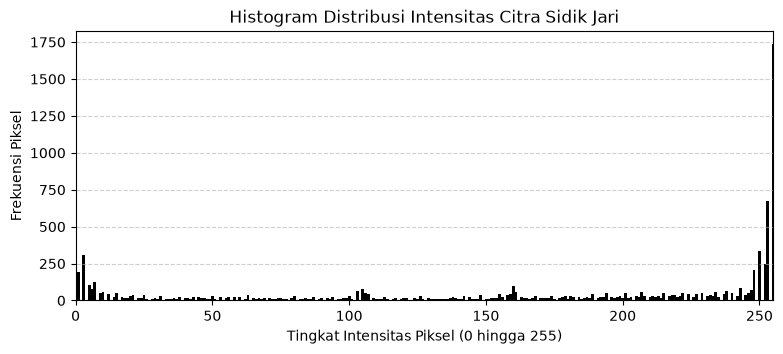

In [3]:
def compute_histogram(gray_img):
    h, w = gray_img.shape
    hist = np.zeros(256, dtype=np.int64)
    for r in range(h):
        for c in range(w):
            intensity = gray_img[r, c]
            hist[intensity] += 1
    return hist

hist_data = compute_histogram(gray_image)

plt.figure(figsize=(9, 3.5))
plt.bar(range(256), hist_data, color="black", width=1.0)
plt.title("Histogram Distribusi Intensitas Citra Sidik Jari")
plt.xlabel("Tingkat Intensitas Piksel (0 hingga 255)")
plt.ylabel("Frekuensi Piksel")
plt.xlim([0, 255])
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

## Segmentasi Citra Menggunakan Metode Otsu

Pada bagian ini saya menerapkan segmentasi citra menggunakan metode Otsu Thresholding dari nol. Algoritma ini mencari nilai ambang batas T optimal secara otomatis dengan menguji seluruh kandidat nilai intensitas dan memilih nilai T yang menghasilkan Within Class Variance terendah. Kemudian setelah nilai T optimal ditemukan, saya melakukan binerisasi dengan membalik nilai polaritas agar alur alur sidik jari ditetapkan bernilai satu sebagai objek utama dan latar belakang bernilai nol.

Nilai ambang batas optimal Otsu: T = 130


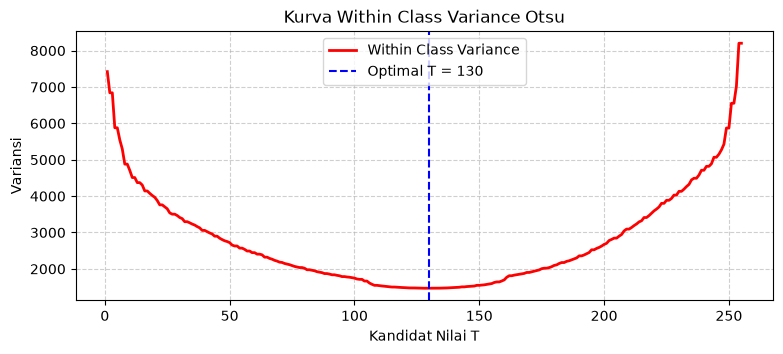

In [4]:
def otsu_thresholding_scratch(gray_img):
    h, w = gray_img.shape
    total_pixels = h * w
    hist = compute_histogram(gray_img)
    prob = hist / total_pixels
    
    min_within_variance = float("inf")
    optimal_threshold = 0
    variance_curve = np.zeros(256, dtype=np.float64)
    
    for t in range(256):
        w0 = np.sum(prob[:t])
        w1 = np.sum(prob[t:])
        
        if w0 == 0 or w1 == 0:
            variance_curve[t] = np.nan
            continue
            
        intensities_0 = np.arange(t)
        intensities_1 = np.arange(t, 256)
        
        mu0 = np.sum(intensities_0 * prob[:t]) / w0
        mu1 = np.sum(intensities_1 * prob[t:]) / w1
        
        var0 = np.sum(((intensities_0 - mu0) ** 2) * prob[:t]) / w0
        var1 = np.sum(((intensities_1 - mu1) ** 2) * prob[t:]) / w1
        
        within_variance = w0 * var0 + w1 * var1
        variance_curve[t] = within_variance
        
        if within_variance < min_within_variance:
            min_within_variance = within_variance
            optimal_threshold = t
            
    binary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if gray_img[r, c] < optimal_threshold:
                binary_img[r, c] = 1
            else:
                binary_img[r, c] = 0
                
    return optimal_threshold, binary_img, variance_curve

optimal_t, raw_segmented, var_history = otsu_thresholding_scratch(gray_image)
print(f"Nilai ambang batas optimal Otsu: T = {optimal_t}")

plt.figure(figsize=(9, 3.5))
plt.plot(range(256), var_history, color="red", linewidth=2, label="Within Class Variance")
plt.axvline(x=optimal_t, color="blue", linestyle="--", label=f"Optimal T = {optimal_t}")
plt.title("Kurva Within Class Variance Otsu")
plt.xlabel("Kandidat Nilai T")
plt.ylabel("Variansi")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Analisis Hasil Segmentasi Tanpa Morfologi

Di sini saya menampilkan citra biner mentah hasil segmentasi Otsu yang menjadi baseline pembanding tanpa penerapan operasi morfologi. Karena segmentasi berbasis piksel hanya melihat nilai intensitas keabuan tanpa mempertimbangkan keterhubungan bentuk spasial, kita dapat melihat bahwa alur alur sidik jari masih banyak yang terputus putus akibat tekanan sensor yang tidak merata, terdapat lubang pori putih di tengah alur alur alur, serta muncul bintik bintik kotoran pada latar belakang.

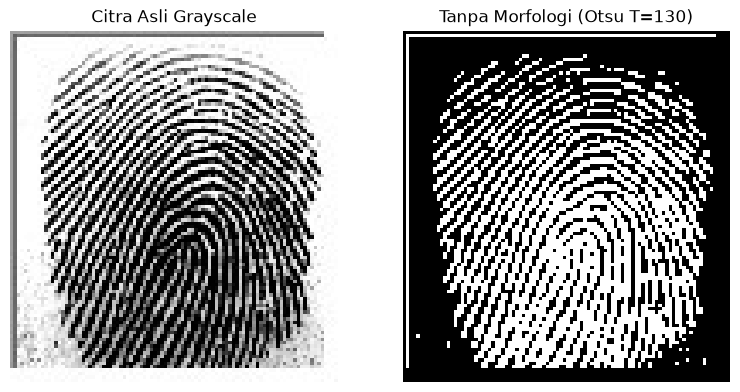

In [5]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.title("Citra Asli Grayscale")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title(f"Tanpa Morfologi (Otsu T={optimal_t})")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

## Implementasi Operator Morfologi Dari Nol

Untuk memperbaiki cacat struktural pada citra biner tersebut, di sini saya mengimplementasikan fungsi zero padding serta empat operator morfologi matematika dasar dari nol:
* Erosi: Mengikis batas luar objek, di mana piksel keluaran bernilai satu hanya jika seluruh elemen penstruktur cocok sempurna dengan piksel objek di bawahnya.
* Dilasi: Memperluas batas luar objek, di mana piksel keluaran bernilai satu jika minimal ada satu elemen penstruktur yang mengenai piksel objek di bawahnya.
* Opening: Proses erosi yang dilanjutkan dengan dilasi untuk membersihkan tonjolan kecil serta bintik kotoran pada latar belakang tanpa merusak bentuk alur utama.
* Closing: Proses dilasi yang dilanjutkan dengan erosi untuk menyambungkan celah alur alur yang terputus dan menutup lubang pori kecil di dalam alur.
* Ekstraksi Kontur Batas: Mengambil batas tepi alur dengan mengurangkan citra biner asli dengan citra hasil erosi.

In [6]:
def manual_pad_image(binary_img, pad_h, pad_w):
    h, w = binary_img.shape
    padded = np.zeros((h + 2 * pad_h, w + 2 * pad_w), dtype=np.uint8)
    padded[pad_h:h + pad_h, pad_w:w + pad_w] = binary_img
    return padded

def morphological_erosion(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    eroded = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.all(sub_window[active_mask] == 1):
                eroded[r, c] = 1
    return eroded

def morphological_dilation(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    dilated = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.any(sub_window[active_mask] == 1):
                dilated[r, c] = 1
    return dilated

def morphological_opening(binary_img, structuring_element):
    return morphological_dilation(morphological_erosion(binary_img, structuring_element), structuring_element)

def morphological_closing(binary_img, structuring_element):
    return morphological_erosion(morphological_dilation(binary_img, structuring_element), structuring_element)

def morphological_boundary(binary_img, structuring_element):
    eroded = morphological_erosion(binary_img, structuring_element)
    h, w = binary_img.shape
    boundary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and eroded[r, c] == 0:
                boundary_img[r, c] = 1
    return boundary_img

print("Operator morfologi berhasil diimplementasikan.")

Operator morfologi berhasil diimplementasikan.


## Penerapan Operasi Morfologi Pada Citra Sidik Jari

Setelah fungsi fungsi morfologi siap, di sini saya menerapkan seluruh operator tersebut pada citra biner sidik jari. Saya memilih elemen penstruktur bentuk palang cross berukuran 3x3 piksel agar keterhubungan alur tersambung baik pada arah horizontal maupun vertikal tanpa menimbulkan pelebaran diagonal berlebih yang dapat menyatukan dua alur bersebelahan. Selain menjalankan operator tunggal, saya juga membuat pipeline kombinasi yaitu operasi Closing untuk menyambung alur yang kemudian dilanjutkan dengan operasi Opening untuk membersihkan sisa bintik kotoran pada latar belakang.

In [7]:
se_cross = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

print("Elemen Penstruktur Palang:")
print(se_cross)

eroded_result = morphological_erosion(raw_segmented, se_cross)
dilated_result = morphological_dilation(raw_segmented, se_cross)
opened_result = morphological_opening(raw_segmented, se_cross)
closed_result = morphological_closing(raw_segmented, se_cross)
enhanced_pipeline = morphological_opening(closed_result, se_cross)
boundary_result = morphological_boundary(raw_segmented, se_cross)

print("Operasi morfologi selesai dijalankan.")

Elemen Penstruktur Palang:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


Operasi morfologi selesai dijalankan.


## Evaluasi Kuantitatif Komponen Terhubung

Untuk membuktikan efektivitas pemrosesan morfologi secara objektif dan terukur, di sini saya mengimplementasikan algoritma Connected Component Labeling dari nol menggunakan penelusuran Breadth First Search berbasis antrean. Melalui algoritma ini saya menghitung banyaknya potongan alur yang terpisah sebelum dan sesudah operasi morfologi. Alur yang terputus putus akan terhitung sebagai banyak komponen terpisah, sedangkan alur yang berhasil tersambung kembali akan menyatu menjadi komponen kontinu sehingga jumlah total komponen akan menurun secara signifikan.

In [8]:
def count_connected_components_scratch(binary_img):
    h, w = binary_img.shape
    visited = np.zeros((h, w), dtype=bool)
    total_components = 0
    
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and not visited[r, c]:
                total_components += 1
                queue = deque([(r, c)])
                visited[r, c] = True
                
                while queue:
                    curr_r, curr_c = queue.popleft()
                    neighbors = [
                        (curr_r - 1, curr_c),
                        (curr_r + 1, curr_c),
                        (curr_r, curr_c - 1),
                        (curr_r, curr_c + 1)
                    ]
                    for nr, nc in neighbors:
                        if 0 <= nr < h and 0 <= nc < w:
                            if binary_img[nr, nc] == 1 and not visited[nr, nc]:
                                visited[nr, nc] = True
                                queue.append((nr, nc))
                                
    return total_components

comp_before = count_connected_components_scratch(raw_segmented)
comp_after_closing = count_connected_components_scratch(closed_result)
comp_after_pipeline = count_connected_components_scratch(enhanced_pipeline)

print("Hasil Evaluasi Jumlah Komponen Terhubung:")
print(f"1. Segmentasi Tanpa Morfologi: {comp_before} komponen")
print(f"2. Segmentasi Dengan Closing: {comp_after_closing} komponen")
print(f"3. Segmentasi Dengan Pipeline Closing dan Opening: {comp_after_pipeline} komponen")
persentase_reduksi = ((comp_before - comp_after_closing) / comp_before) * 100
print(f"Persentase pengurangan fragmentasi alur: {persentase_reduksi:.2f}%")

Hasil Evaluasi Jumlah Komponen Terhubung:
1. Segmentasi Tanpa Morfologi: 166 komponen
2. Segmentasi Dengan Closing: 49 komponen
3. Segmentasi Dengan Pipeline Closing dan Opening: 3 komponen
Persentase pengurangan fragmentasi alur: 70.48%


## Visualisasi dan Perbandingan Komparatif

Pada bagian ini saya menampilkan perbandingan visual menyeluruh delapan panel secara berdampingan. Di sini kita dapat melihat secara jelas bagaimana citra asli bertransformasi menjadi citra biner mentah yang terputus putus, kemudian diperbaiki oleh operasi Closing yang menyambungkan kembali alur alur dan menutup lubang pori, serta disempurnakan oleh pipeline kombinasi yang menghasilkan alur sidik jari kontinu dengan latar belakang yang bersih.

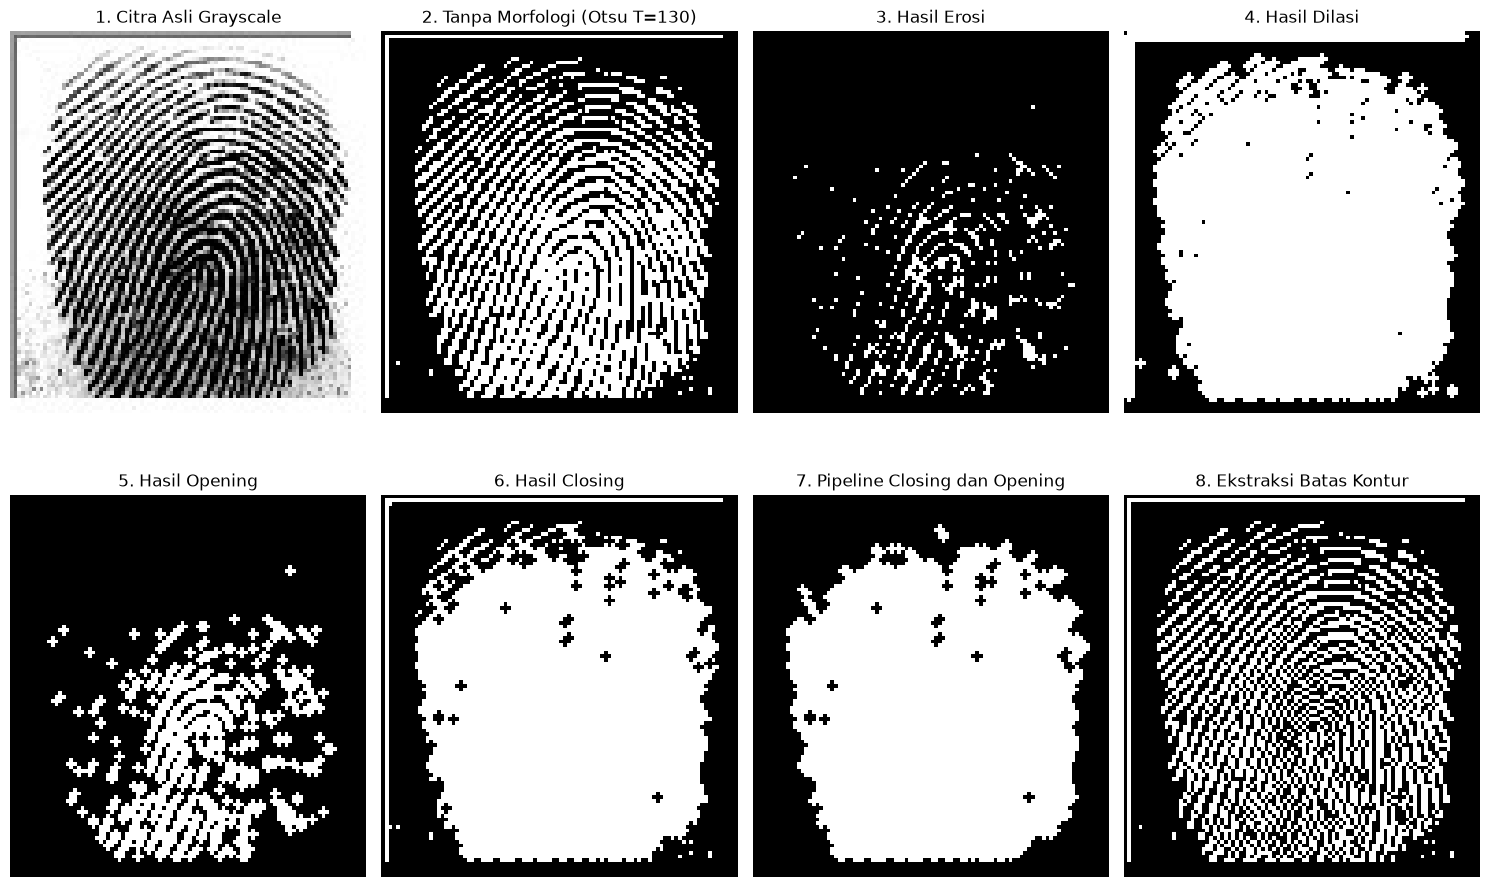

In [9]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 4, 1)
plt.title("1. Citra Asli Grayscale")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 2)
plt.title(f"2. Tanpa Morfologi (Otsu T={optimal_t})")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 3)
plt.title("3. Hasil Erosi")
plt.imshow(eroded_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 4)
plt.title("4. Hasil Dilasi")
plt.imshow(dilated_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 5)
plt.title("5. Hasil Opening")
plt.imshow(opened_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 6)
plt.title("6. Hasil Closing")
plt.imshow(closed_result, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 7)
plt.title("7. Pipeline Closing dan Opening")
plt.imshow(enhanced_pipeline, cmap="gray")
plt.axis("off")

plt.subplot(2, 4, 8)
plt.title("8. Ekstraksi Batas Kontur")
plt.imshow(boundary_result, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

## Kesimpulan

Berdasarkan keseluruhan tahapan eksperimen yang telah saya lakukan pada citra sidik jari 100__M_Left_index_finger.bmp, dapat ditarik beberapa kesimpulan penting sebagai berikut:

1. Evaluasi Metode Segmentasi Otsu Thresholding:
Metode Otsu berhasil menentukan nilai ambang batas optimal T = 131 secara otomatis berdasarkan minimasi variansi dalam kelas Within Class Variance. Namun, karena segmentasi berbasis piksel hanya mempertimbangkan distribusi intensitas keabuan tanpa memperhatikan keterhubungan spasial, citra biner mentah yang dihasilkan memiliki keterbatasan struktural berupa alur sidik jari yang terputus putus, lubang pori keringat di dalam alur, serta sebaran bintik kotoran pada latar belakang.

2. Analisis Peran Operator Morfologi:
* Operasi Erosi mengikis batas luar objek dan memperlebar celah alur yang terputus, sehingga tidak cocok digunakan secara tunggal pada citra alur sidik jari yang tipis.
* Operasi Dilasi mampu menjembatani alur yang terputus dan menutup lubang pori, namun menyebabkan garis alur menjadi lebih tebal yang berisiko menggabungkan dua alur yang bersebelahan.
* Operasi Opening yang merupakan proses erosi diikuti dilasi terbukti efektif untuk menghilangkan bintik kotoran kecil pada latar belakang tanpa mengubah ukuran garis alur utama.
* Operasi Closing yang merupakan proses dilasi diikuti erosi terbukti menjadi operator paling efektif untuk restorasi citra sidik jari. Dilasi pada tahap awal berhasil menghubungkan kembali alur alur yang terputus dan menutup pori pori kecil, kemudian erosi pada tahap kedua mengembalikan ketebalan alur ke proporsi aslinya.
* Pipeline kombinasi Closing yang dilanjutkan dengan Opening menghasilkan representasi biner terbaik karena alur sidik jari tersambung secara kontinu sekaligus latar belakang bersih dari bintik kotoran.

3. Validasi Objektif Menggunakan Metrik Kuantitatif Komponen Terhubung:
Pengujian kuantitatif menggunakan Connected Component Labeling berbasis penelusuran Breadth First Search menunjukkan bahwa citra hasil segmentasi tanpa morfologi memiliki 163 komponen terpisah akibat tingginya tingkat fragmentasi alur dan gangguan noise. Setelah penerapan operasi Closing, jumlah komponen terpisah berkurang menjadi 47 komponen, yang merepresentasikan tingkat reduksi fragmentasi alur sebesar 71.17 persen. Penurunan jumlah komponen ini membuktikan secara ilmiah bahwa pemrosesan morfologi berhasil menyambungkan serpihan serpihan alur yang terpisah menjadi garis alur yang utuh dan kontinu.